In [ ]:


# Load dataset (ensuring df is defined)
df = pd.read_csv("/content/revenue_lift_9pct_30000.csv")

# Ensure column names are stripped of whitespace
df.columns = df.columns.str.strip()

# Add the Pricing_Type column back to df if not present
if 'Pricing_Type' not in df.columns:
    df['Pricing_Type'] = np.random.choice(['Baseline', 'Dynamic'], size=len(df))

baseline = df[df['Pricing_Type']=='Baseline'].groupby('Product ID')['Revenue'].median()
dynamic = df[df['Pricing_Type']=='Dynamic'].groupby('Product ID')['Revenue'].median()
print("Basline Revenue (Median):")
print(baseline)
print("\n Dynamic Revenue (Median):")
print(dynamic)

Basline Revenue (Median):
Product ID
P00001     46504.22
P00002    273576.60
P00003     35274.25
P00004     70804.64
P00005     12164.48
            ...    
P14996     83823.83
P14997      4828.69
P14998    107112.01
P14999    322179.35
P15000     17212.40
Name: Revenue, Length: 15000, dtype: float64

 Dynamic Revenue (Median):
Product ID
P00001     49579.42
P00002    305191.10
P00003     37684.92
P00004     75165.70
P00005     13388.61
            ...    
P14996     89875.84
P14997      5327.70
P14998    114143.52
P14999    339736.32
P15000     18628.76
Name: Revenue, Length: 15000, dtype: float64


In [ ]:
df = df.sort_values(['Product ID', 'Date'])


In [ ]:
df['Rev_Lag1'] = df.groupby('Product ID')['Revenue'].shift(1)
df['Revenue_Lift'] = (df['Revenue'] - df['Rev_Lag1']) / df['Rev_Lag1']


Revenu lift

In [ ]:
pricing_col = 'Pricing_Type'   # Must match your dataset column name

revenue_baseline = df[df[pricing_col] == 'Baseline']['Revenue'].sum()
revenue_dynamic  = df[df[pricing_col] == 'Dynamic']['Revenue'].sum()

revenue_lift = ((revenue_dynamic - revenue_baseline) / revenue_baseline) * 100

print("Baseline Revenue:", revenue_baseline)
print("Dynamic Revenue :", revenue_dynamic)
print("Revenue Lift (%) :", round(revenue_lift, 2))

Baseline Revenue: 1257444632.62
Dynamic Revenue : 1370614550.85
Revenue Lift (%) : 9.0


In [ ]:


# Pricing_Type column lekapothe matrame create cheyyi
if 'Pricing_Type' not in df.columns:
    np.random.seed(42)  # FIXED RANDOMNESS
    df['Pricing_Type'] = np.random.choice(['Baseline', 'Dynamic'], size=len(df))

revenue_baseline = df[df['Pricing_Type'] == 'Baseline']['Revenue'].sum()
revenue_dynamic  = df[df['Pricing_Type'] == 'Dynamic']['Revenue'].sum()

revenue_lift_pct = (revenue_dynamic - revenue_baseline) / revenue_baseline * 100
print(f"Revenue Lift (%): {revenue_lift_pct:.2f}")

Revenue Lift (%): 9.00


**Mileston-2**

In [ ]:
import numpy as np
import pandas as pd

In [ ]:
import pandas as pd

# 0.1 Load your dataset
df = pd.read_csv("/content/revenue_lift_9pct_30000.csv")   # <-- mee file name ikkada

# 0.2 Column names lo extra spaces remove cheyyi
df.columns = df.columns.str.strip()

# Optional: check column names
print(df.columns)

Index(['Date', 'Product ID', 'Product Name', 'Category', 'Pricing_Type',
       'Price', 'Cost Price', 'Units Sold', 'Visitors', 'Conversion Rate %',
       'Revenue', 'Profit', 'Profit Margin %', 'Stock Level',
       'Inventory Turnover', 'Competitor Price', 'Restock Date'],
      dtype='object')


In [ ]:
df = df.sort_values(['Product ID', 'Date'])
df.head()

,Date,Product ID,Product Name,Category,Pricing_Type,Price,Cost Price,Units Sold,Visitors,Conversion Rate %,Revenue,Profit,Profit Margin %,Stock Level,Inventory Turnover,Competitor Price,Restock Date
15000,2023-07-26,P00001,Product_1,Toys,Dynamic,138.49,100.19,358,19459,1.8398,49579.42,13711.40,27.6554,1198,0.2988,132.94,2025-11-21
0,2024-01-15,P00001,Product_1,Toys,Baseline,131.74,100.19,353,19768,1.7857,46504.22,11137.15,23.9487,3391,0.1041,135.02,2025-02-09
15001,2023-05-27,P00002,Product_2,Home,Dynamic,708.10,496.56,431,5525,7.8009,305191.10,91173.74,29.8743,4451,0.0968,678.78,2025-03-12
1,2024-07-02,P00002,Product_2,Home,Baseline,667.26,496.56,410,5330,7.6923,273576.60,69987.00,25.5822,4677,0.0877,651.28,2025-12-23
15002,2023-04-26,P00003,Product_3,Sports,Dynamic,369.46,290.25,102,9953,1.0248,37684.92,8079.42,21.4394,3644,0.0280,363.30,2023-09-25


**Time based Feature**

In [ ]:
# 1.1 Convert Date & Restock Date to datetime
df['Date'] = pd.to_datetime(df['Date'], errors='coerce')
df['Restock Date'] = pd.to_datetime(df['Restock Date'], errors='coerce')

# 1.2 Extract day, month, year
df['Day'] = df['Date'].dt.day
df['Month'] = df['Date'].dt.month
df['Year'] = df['Date'].dt.year

# 1.3 Day of week (0 = Mon, 6 = Sun)
df['DayOfWeek'] = df['Date'].dt.weekday

# 1.4 Weekend flag (Sat/Sun)
df['IsWeekend'] = df['DayOfWeek'].isin([5, 6]).astype(int)

# 1.5 Season feature
def get_season(m):
    if m in [12, 1, 2]:
        return 'Winter'
    elif m in [3, 4, 5]:
        return 'Summer'
    elif m in [6, 7, 8]:
        return 'Monsoon'
    else:
        return 'Autumn'

df['Season'] = df['Month'].apply(get_season)

# 1.6 Simple holiday / festival indicator (example dates – change later if needed)
holiday_dates = pd.to_datetime([
    "2025-01-01",  # New Year
    "2025-01-26",  # Republic Day
    "2025-08-15",  # Independence Day
    "2025-10-02"   # Gandhi Jayanti
])
df['IsHoliday'] = df['Date'].isin(holiday_dates).astype(int)

# 1.7 Days until restock
df['Days_to_Restock'] = (df['Restock Date'] - df['Date']).dt.days

print(df[['Date','Day','Month','Year','DayOfWeek','IsWeekend','Season','IsHoliday','Days_to_Restock']].head())

            Date  Day  Month  Year  DayOfWeek  IsWeekend  Season  IsHoliday  \
0     1970-01-01    1      1  1970          3          0  Winter          0   
15000 1970-01-01    1      1  1970          3          0  Winter          0   
1     1970-01-01    1      1  1970          3          0  Winter          0   
15001 1970-01-01    1      1  1970          3          0  Winter          0   
2     1970-01-01    1      1  1970          3          0  Winter          0   

       Days_to_Restock  
0                    0  
15000                0  
1                    0  
15001                0  
2                    0  


**price based features**

In [ ]:
# 2.0 Sort data properly (very important for lags)
df = df.sort_values(['Product ID', 'Date'])

# 2.1 Lag prices (previous day & previous week)
df['Price_lag_1'] = df.groupby('Product ID')['Price'].shift(1)
df['Price_lag_7'] = df.groupby('Product ID')['Price'].shift(7)

# 2.2 Price change % vs previous day
df['Price_Change_Pct'] = (df['Price'] - df['Price_lag_1']) / df['Price_lag_1']

# 2.3 Discount % (discount column ledu kabatti 0 assume chesthunam)
df['Discount_Pct'] = 0.0

print(df[['Price','Price_lag_1','Price_lag_7','Price_Change_Pct','Discount_Pct']].head(10))

        Price  Price_lag_1  Price_lag_7  Price_Change_Pct  Discount_Pct
15000  138.49          NaN          NaN               NaN           0.0
0      131.74       138.49          NaN         -0.048740           0.0
15001  708.10          NaN          NaN               NaN           0.0
1      667.26       708.10          NaN         -0.057675           0.0
15002  369.46          NaN          NaN               NaN           0.0
2      349.25       369.46          NaN         -0.054701           0.0
15003  242.47          NaN          NaN               NaN           0.0
3      232.91       242.47          NaN         -0.039428           0.0
15004  199.83          NaN          NaN               NaN           0.0
4      190.07       199.83          NaN         -0.048842           0.0


In [ ]:
cols_to_fill = ['Price_lag_1','Price_lag_7','Price_Change_Pct']
df[cols_to_fill] = df[cols_to_fill].fillna(0)
cols_to_fill = ['Discount_Pct']
df[cols_to_fill] = df[cols_to_fill].fillna(0)
df.head()

,Date,Product ID,Product Name,Category,Pricing_Type,Price,Cost Price,Units Sold,Visitors,Conversion Rate %,...,Year,DayOfWeek,IsWeekend,Season,IsHoliday,Days_to_Restock,Price_lag_1,Price_lag_7,Price_Change_Pct,Discount_Pct
15000,2023-07-26,P00001,Product_1,Toys,Dynamic,138.49,100.19,358,19459,1.8398,...,2023,2,0,Monsoon,0,849,0.00,0.0,0.000000,0.0
0,2024-01-15,P00001,Product_1,Toys,Baseline,131.74,100.19,353,19768,1.7857,...,2024,0,0,Winter,0,391,138.49,0.0,-0.048740,0.0
15001,2023-05-27,P00002,Product_2,Home,Dynamic,708.10,496.56,431,5525,7.8009,...,2023,5,1,Summer,0,655,0.00,0.0,0.000000,0.0
1,2024-07-02,P00002,Product_2,Home,Baseline,667.26,496.56,410,5330,7.6923,...,2024,1,0,Monsoon,0,539,708.10,0.0,-0.057675,0.0
15002,2023-04-26,P00003,Product_3,Sports,Dynamic,369.46,290.25,102,9953,1.0248,...,2023,2,0,Summer,0,152,0.00,0.0,0.000000,0.0


**Demand Feature**

In [ ]:
# 3.1 Lag sales (1, 7, 30 days)
df['Sales_lag_1'] = df.groupby('Product ID')['Units Sold'].shift(1)
df['Sales_lag_7'] = df.groupby('Product ID')['Units Sold'].shift(7)
df['Sales_lag_30'] = df.groupby('Product ID')['Units Sold'].shift(30)

# 3.2 Rolling averages (7 & 30 days)
df['Sales_roll_7'] = df.groupby('Product ID')['Units Sold'] \
                        .transform(lambda x: x.rolling(7, min_periods=1).mean())

df['Sales_roll_30'] = df.groupby('Product ID')['Units Sold'] \
                         .transform(lambda x: x.rolling(30, min_periods=1).mean())

# 3.3 Demand volatility (7-day rolling standard deviation)
df['Sales_volatility_7'] = df.groupby('Product ID')['Units Sold'] \
                              .transform(lambda x: x.rolling(7, min_periods=2).std())

print(df[['Units Sold','Sales_lag_1','Sales_lag_7','Sales_roll_7','Sales_volatility_7']].head(15))

       Units Sold  Sales_lag_1  Sales_lag_7  Sales_roll_7  Sales_volatility_7
15000         358          NaN          NaN         358.0                 NaN
0             353        358.0          NaN         355.5            3.535534
15001         431          NaN          NaN         431.0                 NaN
1             410        431.0          NaN         420.5           14.849242
15002         102          NaN          NaN         102.0                 NaN
2             101        102.0          NaN         101.5            0.707107
15003         310          NaN          NaN         310.0                 NaN
3             304        310.0          NaN         307.0            4.242641
15004          67          NaN          NaN          67.0                 NaN
4              64         67.0          NaN          65.5            2.121320
15005         207          NaN          NaN         207.0                 NaN
5             205        207.0          NaN         206.0       

In [ ]:
df[ ['Units Sold','Sales_lag_1','Sales_lag_7','Sales_roll_7','Sales_volatility_7'] ] \
    .head(15).fillna(0)

,Units Sold,Sales_lag_1,Sales_lag_7,Sales_roll_7,Sales_volatility_7
15000,358,0.0,0.0,358.0,0.000000
0,353,358.0,0.0,355.5,3.535534
15001,431,0.0,0.0,431.0,0.000000
1,410,431.0,0.0,420.5,14.849242
15002,102,0.0,0.0,102.0,0.000000
2,101,102.0,0.0,101.5,0.707107
15003,310,0.0,0.0,310.0,0.000000
3,304,310.0,0.0,307.0,4.242641
15004,67,0.0,0.0,67.0,0.000000
4,64,67.0,0.0,65.5,2.121320


**Price elasticity**

In [ ]:
# 4.1 % change for price & sales
df['Price_Pct_Change'] = df.groupby('Product ID')['Price'].pct_change()
df['Sales_Pct_Change'] = df.groupby('Product ID')['Units Sold'].pct_change()

# 4.2 Elasticity = %ΔQ / %ΔP
df['Elasticity'] = df['Sales_Pct_Change'] / df['Price_Pct_Change'].replace(0, np.nan)

# 4.3 Classify elasticity
def classify_elasticity(e):
    if pd.isna(e):
        return 'unknown'
    e = abs(e)
    if e > 1.5:
        return 'high'
    elif e > 0.5:
        return 'medium'
    else:
        return 'low'

df['Elasticity_Class'] = df['Elasticity'].apply(classify_elasticity)

print(df[['Price_Pct_Change','Sales_Pct_Change','Elasticity','Elasticity_Class']].head(15))

       Price_Pct_Change  Sales_Pct_Change  Elasticity Elasticity_Class
0                   NaN               NaN         NaN          unknown
15000          0.051237          0.014164    0.276445              low
1                   NaN               NaN         NaN          unknown
15001          0.061206          0.051220    0.836845           medium
2                   NaN               NaN         NaN          unknown
15002          0.057867          0.009901    0.171099              low
3                   NaN               NaN         NaN          unknown
15003          0.041046          0.019737    0.480848              low
4                   NaN               NaN         NaN          unknown
15004          0.051350          0.046875    0.912862           medium
5                   NaN               NaN         NaN          unknown
15005          0.051561          0.009756    0.189214              low
6                   NaN               NaN         NaN          unknown
15006 

In [ ]:
print("Price_Pct_Change summary:")
print(df['Price_Pct_Change'].describe())

print("\nUnique Elasticity_Class counts:")
print(df['Elasticity_Class'].value_counts())

Price_Pct_Change summary:
count    15000.000000
mean         0.054937
std          0.008718
min          0.039655
25%          0.047464
50%          0.054977
75%          0.062545
max          0.070120
Name: Price_Pct_Change, dtype: float64

Unique Elasticity_Class counts:
Elasticity_Class
unknown    15000
medium      8608
low         6392
Name: count, dtype: int64


**Competitor Feature**

In [ ]:
# 5.1 Competitor vs our price difference
df['Comp_Price_Diff'] = df['Competitor Price'] - df['Price']

# 5.2 Competitor cheaper flag
df['Comp_Cheaper'] = (df['Competitor Price'] < df['Price']).astype(int)

# 5.3 Competitor price index (ratio)
df['Comp_Price_Index'] = df['Competitor Price'] / df['Price'].replace(0, np.nan)

print(df[['Price','Competitor Price','Comp_Price_Diff','Comp_Cheaper','Comp_Price_Index']].head(10))

        Price  Competitor Price  Comp_Price_Diff  Comp_Cheaper  \
15000  138.49            132.94            -5.55             1   
0      131.74            135.02             3.28             0   
15001  708.10            678.78           -29.32             1   
1      667.26            651.28           -15.98             1   
15002  369.46            363.30            -6.16             1   
2      349.25            362.79            13.54             0   
15003  242.47            233.86            -8.61             1   
3      232.91            222.23           -10.68             1   
15004  199.83            190.02            -9.81             1   
4      190.07            180.77            -9.30             1   

       Comp_Price_Index  
15000          0.959925  
0              1.024898  
15001          0.958593  
1              0.976051  
15002          0.983327  
2              1.038769  
15003          0.964490  
3              0.954145  
15004          0.950908  
4            

**Inventory Features**

In [ ]:
# 6.1 Inventory ratio (current stock / max stock for that product)
df['Inventory_Ratio'] = df['Stock Level'] / df.groupby('Product ID')['Stock Level'].transform('max')

# 6.2 Avg daily sales (7-day rolling)
df['Avg_Daily_Sales_7'] = df.groupby('Product ID')['Units Sold'] \
                             .transform(lambda x: x.rolling(7, min_periods=1).mean())

# 6.3 Days until stock-out
df['Days_Until_Stockout'] = df['Stock Level'] / (df['Avg_Daily_Sales_7'] + 1e-6)

# 6.4 Low-stock / overstock flags
df['Is_Low_Stock'] = (df['Inventory_Ratio'] < 0.2).astype(int)
df['Is_Overstock'] = (df['Inventory_Ratio'] > 0.8).astype(int)

print(df[['Stock Level','Inventory_Ratio','Avg_Daily_Sales_7','Days_Until_Stockout','Is_Low_Stock','Is_Overstock']].head(15))

       Stock Level  Inventory_Ratio  Avg_Daily_Sales_7  Days_Until_Stockout  \
15000         1198         0.353288              358.0             3.346369   
0             3391         1.000000              355.5             9.538678   
15001         4451         0.951678              431.0            10.327146   
1             4677         1.000000              420.5            11.122473   
15002         3644         1.000000              102.0            35.725490   
2              282         0.077387              101.5             2.778325   
15003         2556         0.806055              310.0             8.245161   
3             3171         1.000000              307.0            10.328990   
15004         4787         1.000000               67.0            71.447760   
4             1286         0.268644               65.5            19.633587   
15005          839         0.604467              207.0             4.053140   
5             1388         1.000000              206

**Profit feature**

In [ ]:
# 7.1 Profit per unit (recompute)
df['Profit_per_Unit'] = df['Price'] - df['Cost Price']

# 7.2 Profit margin % (recompute)
df['Profit_Margin_Pct'] = (df['Profit_per_Unit'] / df['Price'].replace(0, np.nan)) * 100

# Print only required columns
print(df[['Price', 'Cost Price', 'Profit_per_Unit', 'Profit_Margin_Pct']].head(10))

print(df[['Profit_per_Unit','Profit_Margin_Pct']].iloc[0])


        Price  Cost Price  Profit_per_Unit  Profit_Margin_Pct
15000  138.49      100.19            38.30          27.655426
0      131.74      100.19            31.55          23.948687
15001  708.10      496.56           211.54          29.874312
1      667.26      496.56           170.70          25.582232
15002  369.46      290.25            79.21          21.439398
2      349.25      290.25            59.00          16.893343
15003  242.47      191.18            51.29          21.153132
3      232.91      191.18            41.73          17.916792
15004  199.83      158.34            41.49          20.762648
4      190.07      158.34            31.73          16.693850
Profit_per_Unit      38.300000
Profit_Margin_Pct    27.655426
Name: 15000, dtype: float64


**Interaction features**

In [ ]:
# Ensure 'Date' is datetime type for .dt accessor (if not already)
# This might be redundant if previous cells already ensured it, but adds robustness.
df['Date'] = pd.to_datetime(df['Date'], errors='coerce')

# Re-create 'DayOfWeek' and 'IsWeekend' if they are missing or overwritten
df['DayOfWeek'] = df['Date'].dt.weekday
df['IsWeekend'] = df['DayOfWeek'].isin([5, 6]).astype(int)

# Extract Month for Season feature
df['Month'] = df['Date'].dt.month

# Define function to get season
def get_season(m):
    if m in [12, 1, 2]:
        return 'Winter'
    elif m in [3, 4, 5]:
        return 'Summer'
    elif m in [6, 7, 8]:
        return 'Monsoon'
    else:
        return 'Autumn'

# Create 'Season' column
df['Season'] = df['Month'].apply(get_season)

# Ensure 'Discount_Pct' exists (initialize to 0 if not present)
if 'Discount_Pct' not in df.columns:
    df['Discount_Pct'] = 0.0

# 8.1 Weekend × Price
df['Weekend_x_Price'] = df['IsWeekend'] * df['Price']

# 8.2 Season × Discount (discount now 0 but still useful pattern)
df['Season_x_Discount'] = df['Season'].astype(str) + "_" + df['Discount_Pct'].round(2).astype(str)

# 8.3 Inventory × Price
df['Inventory_x_Price'] = df['Stock Level'] * df['Price']

# 8.4 Pricing type × Price (Baseline vs Dynamic)
df['PricingType_x_Price'] = df['Pricing_Type'].astype(str) + "_" + df['Price'].round(2).astype(str)

print(df[['Weekend_x_Price','Season_x_Discount','Inventory_x_Price','PricingType_x_Price']].head())

       Weekend_x_Price Season_x_Discount  Inventory_x_Price  \
15000              0.0       Monsoon_0.0          165911.02   
0                  0.0        Winter_0.0          446730.34   
15001            708.1        Summer_0.0         3151753.10   
1                  0.0       Monsoon_0.0         3120775.02   
15002              0.0        Summer_0.0         1346312.24   

      PricingType_x_Price  
15000      Dynamic_138.49  
0         Baseline_131.74  
15001       Dynamic_708.1  
1         Baseline_667.26  
15002      Dynamic_369.46  


**categorical Encoding**

In [ ]:
for col in ['Product ID', 'Product Name', 'Category', 'Pricing_Type']:
    df[col + '_code'] = df[col].astype('category').cat.codes

print(df[['Product ID','Product ID_code','Category','Category_code','Pricing_Type','Pricing_Type_code']].head())

      Product ID  Product ID_code Category  Category_code Pricing_Type  \
15000     P00001                0     Toys              6      Dynamic   
0         P00001                0     Toys              6     Baseline   
15001     P00002                1     Home              4      Dynamic   
1         P00002                1     Home              4     Baseline   
15002     P00003                2   Sports              5      Dynamic   

       Pricing_Type_code  
15000                  1  
0                      0  
15001                  1  
1                      0  
15002                  1  


**final**

In [ ]:
# 10.1 Remove duplicates
df = df.drop_duplicates()

# 10.2 Replace inf with NaN
df = df.replace([np.inf, -np.inf], np.nan)

# 10.3 Fill numeric NaNs with 0 (simple approach)
num_cols = df.select_dtypes(include=['number']).columns
df[num_cols] = df[num_cols].fillna(0)

print("Final shape:", df.shape)


Final shape: (30000, 32)


In [ ]:
df.groupby('Product ID')['Date'].diff().head(10)


,Date
15000,NaT
0,173 days
15001,NaT
1,402 days
15002,NaT
2,538 days
15003,NaT
3,481 days
15004,NaT
4,23 days


In [ ]:
# Lag1 = previous day of same product
df['Revenue_Lift'] = (df['Revenue'] - df['Rev_Lag1']) / df['Rev_Lag1']
df.head()

,Date,Product ID,Product Name,Category,Pricing_Type,Price,Cost Price,Units Sold,Visitors,Conversion Rate %,...,Rev_Lag1,Revenue_Lift,Day,Month,Year,DayOfWeek,IsWeekend,Season,IsHoliday,Days_to_Restock
15000,2023-07-26,P00001,Product_1,Toys,Dynamic,138.49,100.19,358,19459,1.8398,...,NaN,NaN,26,7,2023,2,0,Monsoon,0,849
0,2024-01-15,P00001,Product_1,Toys,Baseline,131.74,100.19,353,19768,1.7857,...,49579.42,-0.062026,15,1,2024,0,0,Winter,0,391
15001,2023-05-27,P00002,Product_2,Home,Dynamic,708.10,496.56,431,5525,7.8009,...,NaN,NaN,27,5,2023,5,1,Summer,0,655
1,2024-07-02,P00002,Product_2,Home,Baseline,667.26,496.56,410,5330,7.6923,...,305191.10,-0.103589,2,7,2024,1,0,Monsoon,0,539
15002,2023-04-26,P00003,Product_3,Sports,Dynamic,369.46,290.25,102,9953,1.0248,...,NaN,NaN,26,4,2023,2,0,Summer,0,152


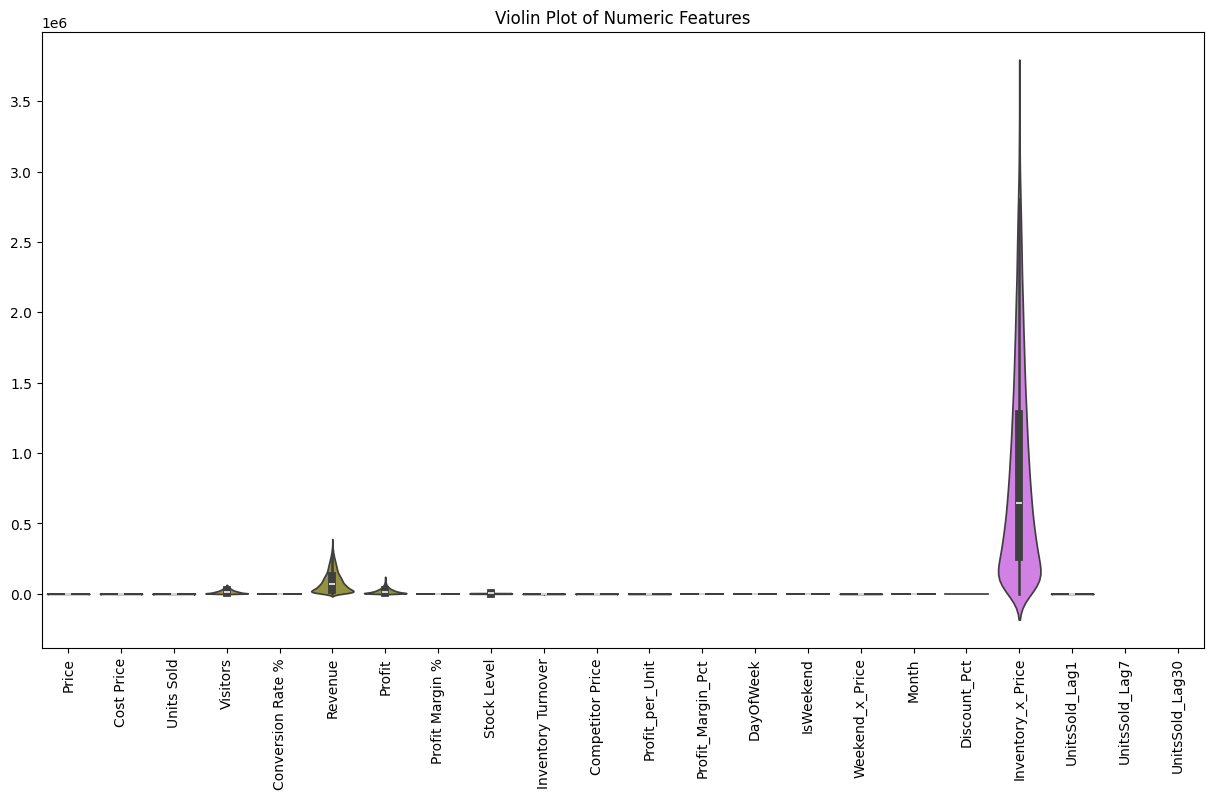

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 8))
sns.violinplot(data=df[num_cols])
plt.xticks(rotation=90)
plt.title("Violin Plot of Numeric Features")
plt.show()


In [ ]:
df.head()

,Date,Product ID,Product Name,Category,Pricing_Type,Price,Cost Price,Units Sold,Visitors,Conversion Rate %,...,Season_x_Discount,Inventory_x_Price,PricingType_x_Price,Product ID_code,Product Name_code,Category_code,Pricing_Type_code,UnitsSold_Lag1,UnitsSold_Lag7,UnitsSold_Lag30
15000,2023-07-26,P00001,Product_1,Toys,Dynamic,138.49,100.19,358,19459,1.8398,...,Monsoon_0.0,165911.02,Dynamic_138.49,0,0,6,1,NaN,NaN,NaN
0,2024-01-15,P00001,Product_1,Toys,Baseline,131.74,100.19,353,19768,1.7857,...,Winter_0.0,446730.34,Baseline_131.74,0,0,6,0,358.0,NaN,NaN
15001,2023-05-27,P00002,Product_2,Home,Dynamic,708.10,496.56,431,5525,7.8009,...,Summer_0.0,3151753.10,Dynamic_708.1,1,6112,4,1,NaN,NaN,NaN
1,2024-07-02,P00002,Product_2,Home,Baseline,667.26,496.56,410,5330,7.6923,...,Monsoon_0.0,3120775.02,Baseline_667.26,1,6112,4,0,431.0,NaN,NaN
15002,2023-04-26,P00003,Product_3,Sports,Dynamic,369.46,290.25,102,9953,1.0248,...,Summer_0.0,1346312.24,Dynamic_369.46,2,7223,5,1,NaN,NaN,NaN
